In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
housing = fetch_openml(
    name = 'boston',
    version=1,
    as_frame=True
)
X = housing.data
y = pd.to_numeric(housing.target)
print("Dataset loaded successfully!")
print("Features:", X.shape)
print("Target:", y.shape)

display(X.head())

Dataset loaded successfully!
Features: (506, 13)
Target: (506,)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33


In [3]:
X.shape


(506, 13)

In [4]:
y.shape

(506,)

In [5]:
X.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
dtype: int64

In [6]:
print("\nTarget statistics:")
print(y.describe())


Target statistics:
count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 404
Testing samples: 102


In [8]:
models = {
    "Linear Regression" : make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Decision Tree" : DecisionTreeRegressor(
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    "Gradient Cooling" : GradientBoostingRegressor(
        random_state=42
    ),
    "KNN" :make_pipeline(
        StandardScaler(),
        SVR()
    ),
    
}
print("No. of Modeles" , len(models))
print("Models:", list(models.keys()))

No. of Modeles 5
Models: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Cooling', 'KNN']


In [12]:
results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)

print("All models trained successfully!")
display(results_df.sort_values("RMSE"))

All models trained successfully!


,Model,MAE,RMSE,R2 Score
3,Gradient Cooling,1.912243,2.491759,0.915334
2,Random Forest,2.039539,2.810963,0.892253
1,Decision Tree,2.394118,3.227395,0.857963
0,Linear Regression,3.189092,4.928602,0.668759
4,KNN,2.731716,5.066413,0.649977


In [13]:
best_row = results_df.loc[results_df["RMSE"].idxmin()]

best_model_name = best_row["Model"]
best_model = trained_models[best_model_name]

print("BEST MODEL:", best_model_name)
print("MAE:", round(best_row["MAE"], 3))
print("RMSE:", round(best_row["RMSE"], 3))
print("R2 Score:", round(best_row["R2 Score"], 3))

BEST MODEL: Gradient Cooling
MAE: 1.912
RMSE: 2.492
R2 Score: 0.915


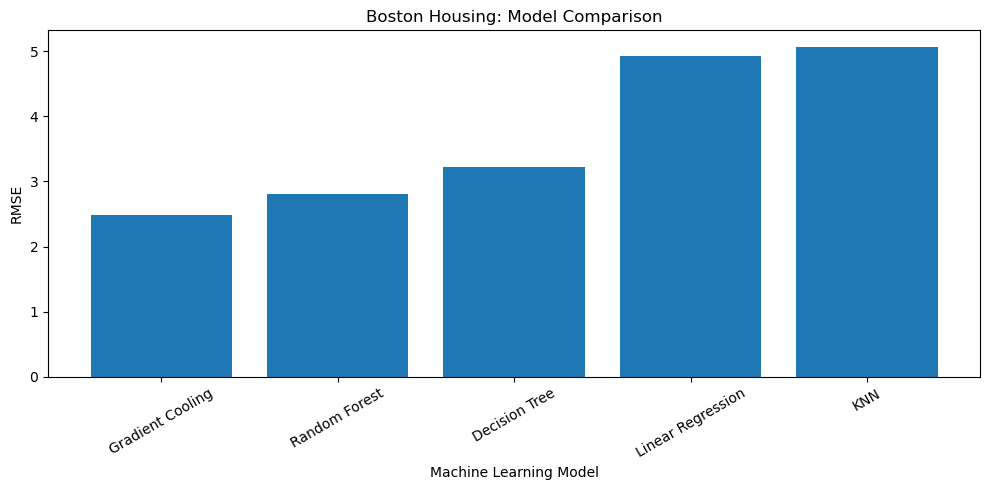

In [14]:
results_df = results_df.sort_values("RMSE")

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE")
plt.title("Boston Housing: Model Comparison")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [15]:
predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": predictions
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,23.6,23.449761
1,32.4,31.461360
2,13.6,17.705313
3,22.8,24.022573
4,16.1,17.681144
5,20.0,22.031128
6,17.8,18.149588
7,14.0,13.830452
8,19.6,20.616193
9,16.8,21.042857


In [17]:
import joblib
joblib.dump(
    best_model,
    "best_boston_housing_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


In [18]:
report = {
    "Dataset": "Boston Housing",
    "Models Tested": len(models),
    "Best Model": best_model_name,
    "Best MAE": round(best_row["MAE"], 3),
    "Best RMSE": round(best_row["RMSE"], 3),
    "Best R2 Score": round(best_row["R2 Score"], 3)
}

report_df = pd.DataFrame(
    report.items(),
    columns=["Metric", "Value"]
)

display(report_df)

report_df.to_csv(
    "model_selection_report.csv",
    index=False
)

print("Final report saved successfully!")

,Metric,Value
0,Dataset,Boston Housing
1,Models Tested,5
2,Best Model,Gradient Cooling
3,Best MAE,1.912
4,Best RMSE,2.492
5,Best R2 Score,0.915


Final report saved successfully!
